In [31]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from random import choice, randint, shuffle, seed
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

seed(42)

# Генерация набора данных

In [32]:
class CharDataset:
    NEEDED_FOLDERS = {'0','1','2','3','4','5','6','7','8','9',
                      '+','-','times'}

    def __init__(self, data_path, img_size=45, max_images_per_char=2000):
        self.data_path = data_path
        self.img_size = img_size
        self.max_images_per_char = max_images_per_char

        self.name_folders = self._get_character_folders(data_path)
        self.available_chars = self._replace_times_with_asterisk(self.name_folders)
        self.char_images = self._load_preprocess_images()

    @classmethod
    def _get_character_folders(cls, data_path):
        return sorted(
            item for item in os.listdir(data_path)
            if os.path.isdir(os.path.join(data_path, item))
            and item in cls.NEEDED_FOLDERS
        )

    @staticmethod
    def _replace_times_with_asterisk(name_folders):
        return ['*' if ch == 'times' else ch for ch in name_folders]

    def _load_preprocess_images(self):
        char_images = {}
        for original_char, display_char in zip(self.name_folders, self.available_chars):
            char_path = os.path.join(self.data_path, original_char)
            images = []
            all_files = [f for f in os.listdir(char_path)
                         if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
            shuffle(all_files)
            for file in all_files[:self.max_images_per_char]:
                img = cv2.imread(os.path.join(char_path, file))
                if img is not None:
                    if img.shape[:2] != (self.img_size, self.img_size):
                        img = cv2.resize(img, (self.img_size, self.img_size))
                    images.append(img)
            char_images[display_char] = images
        return char_images

    def get_all_data(self):
        X, y = [], []
        for char_idx, char in enumerate(self.available_chars):
            for img in self.char_images[char]:
                X.append(img)
                y.append(char_idx)
        return np.array(X), np.array(y), self.available_chars

    def __len__(self):
        return sum(len(imgs) for imgs in self.char_images.values())

    def __repr__(self):
        return (f"CharDataset(data_path='{self.data_path}', "
                f"img_size={self.img_size}, chars={len(self.available_chars)}, "
                f"total_images={len(self)}, max_per_char={self.max_images_per_char})")

    def print_loading_stats(self):
        print("\nСтатистика загрузки изображений:")
        total = 0
        for char, images in self.char_images.items():
            print(f"  '{char}': {len(images)} изображений")
            total += len(images)
        print(f"Всего загружено: {total} изображений")

## Генератор последовательностей

In [33]:
class SequenceGenerator:
    def __init__(self, pool, size, max_words=4, max_word_len=5, char_gap=4):
        self.pool, self.chars, self.size = pool, list(pool), size
        self.max_words, self.max_word_len, self.char_gap = max_words, max_word_len, char_gap

    def generate_text(self):
        words = [''.join(choice(self.chars) for _ in range(randint(1, self.max_word_len)))
                 for _ in range(randint(2, self.max_words))]
        return ' '.join(words)

    def text_to_images(self, text):
        return [choice(self.pool[ch]) for ch in text if ch != ' ']

    def build_image(self, text, images):
        it = iter(images)
        gap = np.full((self.size, self.char_gap, 3), 255, np.uint8)
        parts = []
        for ch in text:
            parts.append(np.full((self.size, self.size, 3), 255, np.uint8) if ch == ' ' else next(it))
            parts.append(gap)
        return cv2.copyMakeBorder(np.hstack(parts), 10, 10, 10, 10, cv2.BORDER_CONSTANT, value=(255, 255, 255))

    def generate_dataset(self, n):
        data = []
        for _ in range(n):
            text = self.generate_text()
            images = self.text_to_images(text)
            data.append((text, images, self.build_image(text, images)))
        return data

# Классификация

In [34]:
def symbol_to_vector(img, size=45):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img.copy()
    gray = cv2.erode(gray, np.ones((3, 3), np.uint8), iterations=1)
    gray = cv2.bitwise_not(gray)
    pts = cv2.findNonZero((gray > 127).astype(np.uint8))
    if pts is None:
        return np.zeros(size * size, np.float32)
    x, y, w, h = cv2.boundingRect(pts)
    crop = gray[y:y + h, x:x + w]
    side = max(w, h)
    square = np.zeros((side, side), np.uint8)
    square[(side - h) // 2:(side - h) // 2 + h, (side - w) // 2:(side - w) // 2 + w] = crop
    return cv2.resize(square, (size, size)).astype(np.float32).ravel() / 255

class CharClassifier:
    def __init__(self, char_dataset):
        self.char_dataset = char_dataset
        self.size = char_dataset.img_size
        self.model = None

    def prepare_data(self, val_size=0.15, test_size=0.15, random_state=42):
        X, y, self.char_labels = self.char_dataset.get_all_data()
        idx = np.arange(len(X))
        idx_tr, idx_rest = train_test_split(idx, test_size=val_size + test_size,
                                            random_state=random_state, stratify=y)
        idx_val, idx_te = train_test_split(idx_rest, test_size=test_size / (val_size + test_size),
                                           random_state=random_state, stratify=y[idx_rest])
        vec = lambda ids: np.array([symbol_to_vector(X[i], self.size) for i in ids])
        self.X_train, self.y_train = vec(idx_tr), y[idx_tr]
        self.X_val, self.y_val = vec(idx_val), y[idx_val]
        self.X_test, self.y_test = vec(idx_te), y[idx_te]
        self.test_pool = {c: [X[i] for i in idx_te if y[i] == k] for k, c in enumerate(self.char_labels)}

    def find_optimal_k(self, k_range=range(1, 16, 2)):
        self.accuracy_history = {}
        for k in k_range:
            knn = KNeighborsClassifier(n_neighbors=k).fit(self.X_train, self.y_train)
            self.accuracy_history[k] = accuracy_score(self.y_val, knn.predict(self.X_val))
        self.best_k = max(self.accuracy_history, key=self.accuracy_history.get)
        return self.best_k, self.accuracy_history

    def train_best_model(self):
        self.model = KNeighborsClassifier(n_neighbors=self.best_k).fit(self.X_train, self.y_train)

    def evaluate_model(self):
        y_pred = self.model.predict(self.X_test)
        return accuracy_score(self.y_test, y_pred), y_pred

# Распознавание

In [35]:
class SequenceRecognizer:
    def __init__(self, classifier, size, space_ratio=1.0, merge_overlaps=True):
        self.clf, self.size = classifier, size
        self.space_gap = space_ratio * size
        self.merge_overlaps = merge_overlaps

    def segment_image(self, seq_image):
        gray = cv2.cvtColor(seq_image, cv2.COLOR_BGR2GRAY)
        gray = cv2.bitwise_not(cv2.erode(gray, np.ones((3, 3), np.uint8), iterations=1))
        base = cv2.copyMakeBorder(gray, 3, 3, 3, 3, cv2.BORDER_CONSTANT, value=0)
        _, thresh = cv2.threshold(base, 127, 255, 0)
        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        boxes = [cv2.boundingRect(c) for c in contours]
        boxes = [b for b in boxes if b[2] * b[3] > 50]
        boxes.sort(key=lambda b: b[0])
        merged = []
        for x, y, w, h in boxes:
            if self.merge_overlaps and merged and x < merged[-1][0] + merged[-1][1]:
                px, pw = merged[-1]
                merged[-1] = (px, max(px + pw, x + w) - px)
            else:
                merged.append((x, w))
        return [(x - 3, w) for x, w in merged]

    def recognize(self, seq_image):
        spans = self.segment_image(seq_image)
        vecs = [symbol_to_vector(seq_image[:, max(x, 0):x + w], self.size) for x, w in spans]
        pred = self.clf.model.predict(np.array(vecs))
        out = self.clf.char_labels[pred[0]]
        for i in range(1, len(spans)):
            gap = spans[i][0] - (spans[i - 1][0] + spans[i - 1][1])
            if gap > self.space_gap:
                out += ' '
            out += self.clf.char_labels[pred[i]]
        return out

Классы: ['+', '-', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '*']
Train: 18200, val: 3900, test: 3900
k =  1   val accuracy = 0.9587   <-- лучшее
k =  3   val accuracy = 0.9218
k =  5   val accuracy = 0.9026
k =  7   val accuracy = 0.8956
k =  9   val accuracy = 0.8851
k = 11   val accuracy = 0.8726
k = 13   val accuracy = 0.8628
k = 15   val accuracy = 0.8572
Accuracy на тесте: 0.9569

Сгенерирована строка: '8-010 4 +'
Найдено объектов: 7 (символов в строке: 7)
k-NN (k = 1) распознал символы: 8-0104+
Исходно:    '8-010 4 +'
Распознано: '8-010 4 +'  ->  ВЕРНО


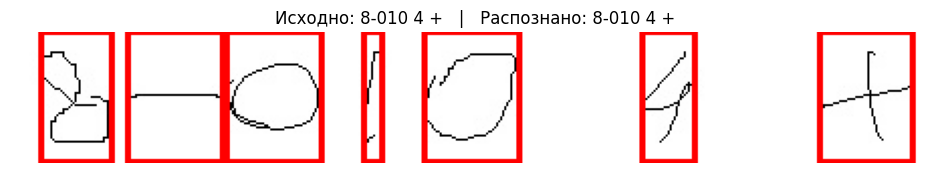


200 строк: символов верно 94.6%, строк целиком 63.0%


In [36]:
char_dataset = CharDataset('./data', img_size=45, max_images_per_char=2000)
size = char_dataset.img_size
print("Классы:", char_dataset.available_chars)

classifier = CharClassifier(char_dataset)
classifier.prepare_data()
print(f"Train: {len(classifier.y_train)}, val: {len(classifier.y_val)}, test: {len(classifier.y_test)}")

best_k, history = classifier.find_optimal_k()
for k, acc in history.items():
    print(f"k = {k:>2}   val accuracy = {acc:.4f}" + ("   <-- лучшее" if k == best_k else ""))

classifier.train_best_model()
test_acc, _ = classifier.evaluate_model()
print(f"Accuracy на тесте: {test_acc:.4f}")

generator = SequenceGenerator(classifier.test_pool, size)
recognizer = SequenceRecognizer(classifier, size)

true_text, _, seq_image = generator.generate_dataset(1)[0]
true_chars = true_text.replace(' ', '')

print(f"\nСгенерирована строка: '{true_text}'")

spans = recognizer.segment_image(seq_image)
print(f"Найдено объектов: {len(spans)} (символов в строке: {len(true_chars)})")

vecs = np.array([symbol_to_vector(seq_image[:, max(x, 0):x + w], size) for x, w in spans])
preds = [classifier.char_labels[i] for i in classifier.model.predict(vecs)]
print(f"k-NN (k = {best_k}) распознал символы: {''.join(preds)}")

result = recognizer.recognize(seq_image)
print(f"Исходно:    '{true_text}'")
print(f"Распознано: '{result}'  ->  {'ВЕРНО' if result == true_text else 'есть ошибки'}")

vis = cv2.cvtColor(seq_image, cv2.COLOR_BGR2RGB)
for x, w in spans:
    cv2.rectangle(vis, (max(x, 0), 0), (x + w, vis.shape[0] - 1), (255, 0, 0), 2)
plt.figure(figsize=(12, 2))
plt.imshow(vis)
plt.title(f"Исходно: {true_text}   |   Распознано: {result}")
plt.axis("off")
plt.show()

data = generator.generate_dataset(200)
preds_all = [recognizer.recognize(img) for _, _, img in data]
line_acc = np.mean([t == p for (t, _, _), p in zip(data, preds_all)])
total = ok = 0
for (t, _, _), p in zip(data, preds_all):
    a, b = t.replace(' ', ''), p.replace(' ', '')
    total += len(a)
    ok += sum(x == y for x, y in zip(a, b))
print(f"\n200 строк: символов верно {ok / total:.1%}, строк целиком {line_acc:.1%}")